# 05 — Explainability, segmentation and the retention plan

A probability is not an answer. "82% likely to leave" tells a retention agent nothing they
can say on a call. This notebook closes the loop:

```
probability -> reason -> risk band -> revenue exposure -> a named play with an owner and a cost
```

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#EAE6DF",
                     "axes.facecolor": "white", "figure.facecolor": "white",
                     "axes.edgecolor": "#C9C4BA", "axes.axisbelow": True,
                     "legend.frameon": False})
SLATE, CLAY, AMBER = "#335C67", "#9E2A2B", "#E09F3E"


In [2]:
%matplotlib inline
import joblib, shap
from explain import compute_shap, humanise, top_drivers

model = joblib.load("../models/churn_model.pkl")
meta = joblib.load("../models/model_metadata.pkl")
score = pd.read_parquet("../data/processed/features_score.parquet")
feature_cols = meta["feature_columns"]

sample = score.sample(6000, random_state=0)
sv, Xt, names, base = compute_shap(model, sample[feature_cols])
print(f"SHAP values: {sv.shape[0]:,} customers x {sv.shape[1]} features")
print(f"Base value (log-odds): {base:.3f}  ->  {1/(1+np.exp(-base)):.2%} average risk")

SHAP values: 6,000 customers x 74 features
Base value (log-odds): 0.225  ->  55.60% average risk


## Global drivers

SHAP values are additive in log-odds space, so a feature's mean absolute value is a genuine
measure of how much it moves predictions — not a proxy like split counts.

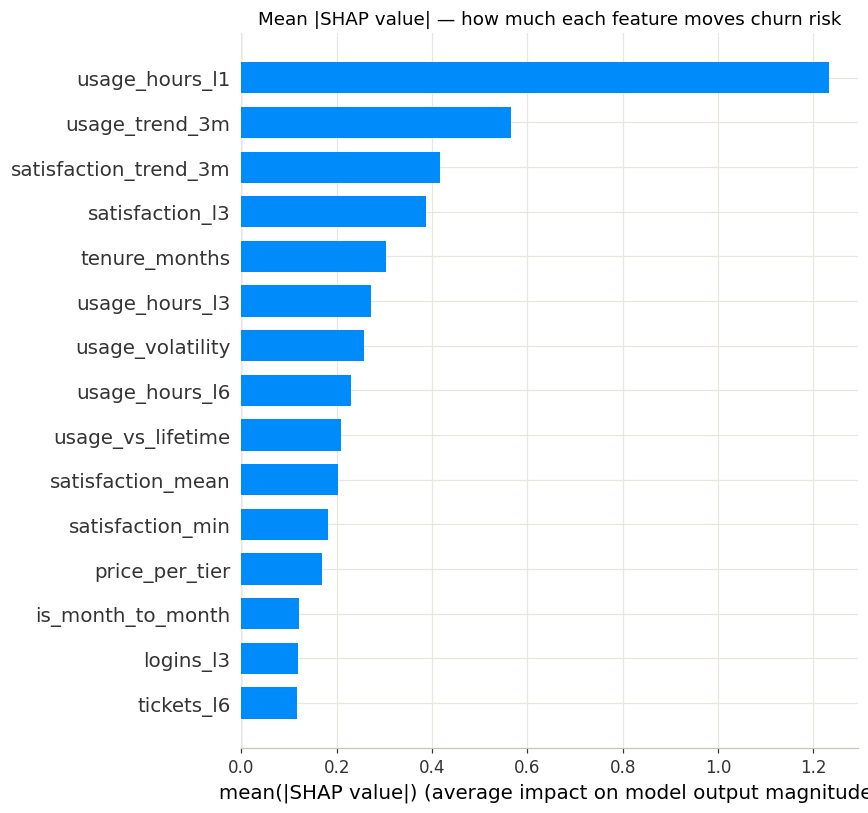

In [3]:
shap.summary_plot(sv, Xt, feature_names=names, plot_type="bar", max_display=15, show=False)
plt.title("Mean |SHAP value| — how much each feature moves churn risk")
plt.tight_layout()
plt.show()

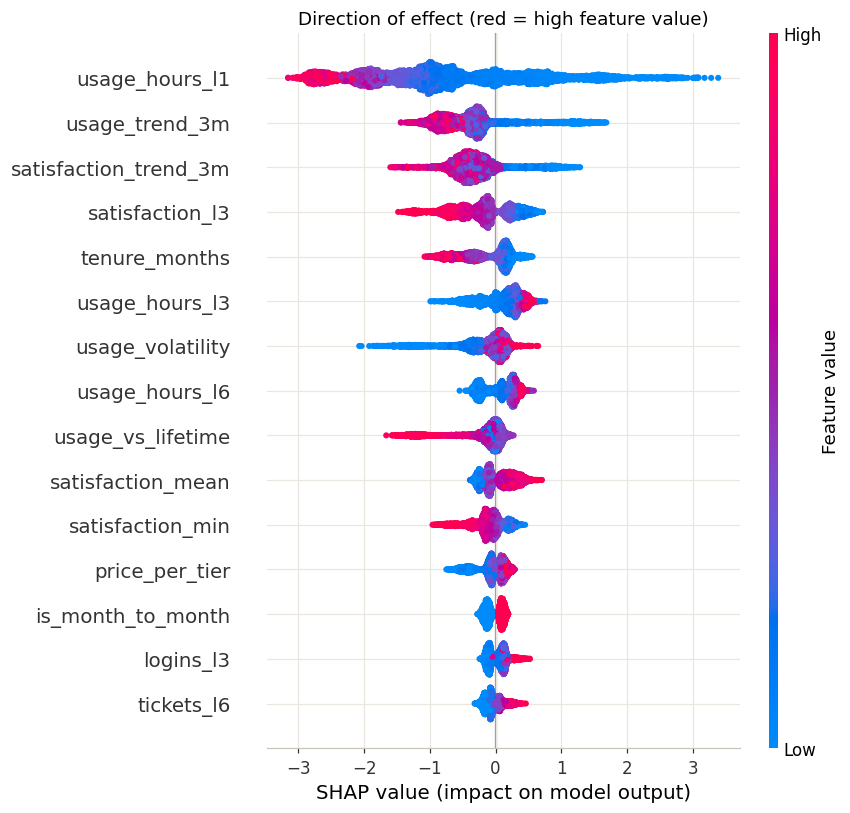

In [4]:
shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False)
plt.title("Direction of effect (red = high feature value)")
plt.tight_layout()
plt.show()

Read the beeswarm as: *high recent usage (red) sits on the left, pushing risk down; low
usage (blue) sits on the right, pushing risk up.* The model has learned the disengagement
story the EDA showed, without being told it.

In [5]:
imp = (pd.DataFrame({"feature": names, "mean_abs_shap": np.abs(sv).mean(0)})
       .sort_values("mean_abs_shap", ascending=False).head(12).reset_index(drop=True))
imp.round(4)

,feature,mean_abs_shap
0,usage_hours_l1,1.2318
1,usage_trend_3m,0.5653
2,satisfaction_trend_3m,0.4167
3,satisfaction_l3,0.3871
4,tenure_months,0.3027
5,usage_hours_l3,0.2710
6,usage_volatility,0.2575
7,usage_hours_l6,0.2307
8,usage_vs_lifetime,0.2081
9,satisfaction_mean,0.2024


## How a single driver behaves

A dependence plot shows the shape of the relationship — where the risk actually turns.

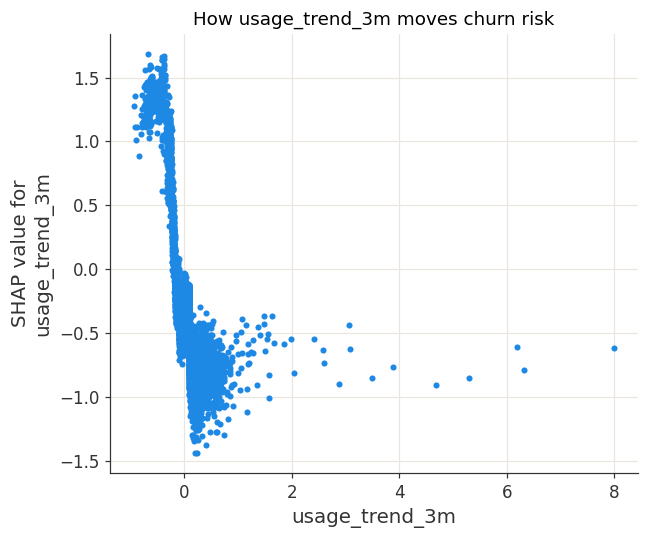

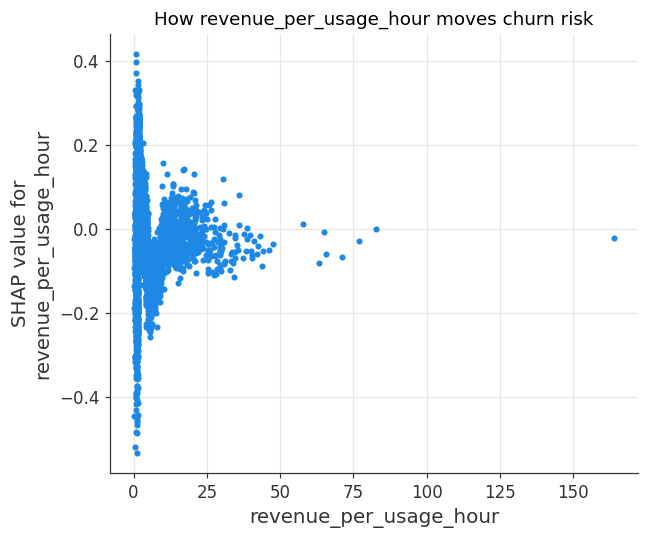

In [6]:
for feat in ["usage_trend_3m", "revenue_per_usage_hour"]:
    j = names.index(feat)
    shap.dependence_plot(j, sv, Xt, feature_names=names, interaction_index=None, show=False)
    plt.title(f"How {feat} moves churn risk")
    plt.tight_layout()
    plt.show()

## One customer, explained

This is the artefact the dashboard renders and the retention agent reads.

Customer      : Julie Henry (CUS027204)
Plan          : Enterprise Month-to-month at $249.99/mo
Tenure        : 39 months
Churn risk    : 99.8%


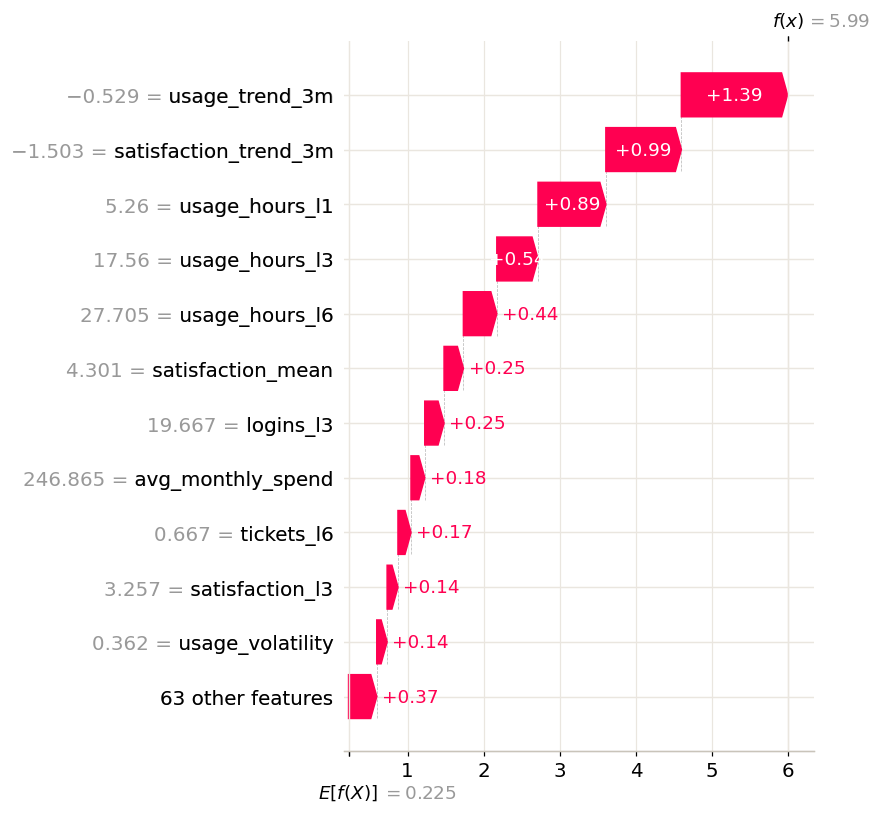

In [7]:
proba = model.predict_proba(sample[feature_cols])[:, 1]
i = int(np.argmax(proba))
cust = sample.iloc[i]

print(f"Customer      : {cust.customer_name} ({cust.customer_id})")
print(f"Plan          : {cust.plan_name} at ${cust.monthly_price:.2f}/mo")
print(f"Tenure        : {cust.tenure_months:.0f} months")
print(f"Churn risk    : {proba[i]:.1%}")

shap.plots.waterfall(shap.Explanation(values=sv[i], base_values=base, data=Xt[i],
                                      feature_names=names), max_display=12, show=False)
plt.tight_layout()
plt.show()

In [8]:
drivers = top_drivers(sv[[i]], Xt[[i]], names, pd.Series([cust.customer_id]))
print("Pushing this customer towards leaving:")
for r in drivers[drivers.direction == "increases risk"].itertuples():
    print(f"   + {r.explanation:<52} ({r.shap_value:+.2f})")
print("\nHolding this customer in place:")
for r in drivers[drivers.direction == "reduces risk"].itertuples():
    print(f"   - {r.explanation:<52} ({r.shap_value:+.2f})")

Pushing this customer towards leaving:
   + Usage down 53% versus the prior quarter              (+1.39)
   + Satisfaction down 1.5 points                         (+0.99)
   + Usage hours l1: 5.26                                 (+0.89)
   + Recent usage averages 17.6 hours per month           (+0.54)
   + Usage hours l6: 27.70                                (+0.44)
   + Lifetime satisfaction score of 4.3 out of 5          (+0.25)

Holding this customer in place:
   - Tickets take 10.9 hours to resolve on average        (-0.05)
   - Recent usage is 53% of this customer's own norm      (-0.05)
   - 39 months as a customer                              (-0.08)
   - Spend up 5% versus the prior quarter                 (-0.08)


The `humanise()` layer in `src/explain.py` maps each feature to a sentence with the
customer's own value substituted in. That is what makes the output usable by someone who has
never heard of a log-odds.

## Risk segmentation and revenue exposure

In [9]:
scored = pd.read_parquet("../data/processed/scored_customers.parquet")
seg = pd.read_csv("../reports/risk_segment_summary.csv", index_col=0)
seg[["customers", "avg_probability", "avg_monthly_spend", "annual_revenue", "arr_at_risk",
     "avg_tenure_months", "month_to_month_share"]]

,customers,avg_probability,avg_monthly_spend,annual_revenue,arr_at_risk,avg_tenure_months,month_to_month_share
risk_band,,,,,,,
Low,29884,0.07,61.15,21928801.18,1661285.44,36.10,0.43
Medium,2859,0.45,73.44,2519508.30,1128875.85,26.11,0.63
High,1838,0.91,73.33,1617378.62,1482091.03,27.73,0.63


In [10]:
import json
impact = json.load(open("../reports/business_impact.json"))
high = scored[scored.risk_band == "High"]

print(f"Active customers        {impact['active_customers']:,}")
print(f"High-risk customers     {impact['high_risk_customers']:,} "
      f"({impact['high_risk_customers']/impact['active_customers']:.1%} of the book)")
print(f"ARR in the high band    ${impact['high_band_annual_revenue']:,.0f}")
print(f"Probability-weighted ARR at risk  ${impact['arr_at_risk_total']:,.0f}")
print(f"\nProgramme cost          ${impact['programme_cost']:,.0f}")
print(f"Expected revenue saved  ${impact['expected_revenue_saved']:,.0f}")
print(f"Net benefit             ${impact['net_benefit']:,.0f}  (ROI {impact['roi_multiple']}x)")

Active customers        34,581
High-risk customers     1,838 (5.3% of the book)
ARR in the high band    $1,617,379
Probability-weighted ARR at risk  $4,272,252

Programme cost          $229,453
Expected revenue saved  $783,290
Net benefit             $553,837  (ROI 3.41x)


### A note on CLV

The obvious formula — `monthly revenue x expected lifetime` — quietly breaks the business
case. A customer about to cancel has a *short* expected lifetime, so their CLV is small, so
the model recommends ignoring the most urgent accounts in the book.

The fix is to value a save against the **counterfactual**: what the customer would be worth
if the intervention works and they revert to healthy-book behaviour.

```
monthly hazard  h = 1 - (1 - p_horizon) ** (1 / horizon_months)
survival factor q = (1 - h) / (1 + discount_rate)
CLV               = monthly_margin * q / (1 - q)
CLV if retained   = same formula at a healthy 2% monthly hazard
```

In [11]:
cmp = scored.groupby("risk_band")[["clv", "clv_if_retained", "expected_saved_margin",
                                   "action_cost", "action_expected_value"]].mean().round(0)
cmp.reindex(["Low", "Medium", "High"])

,clv,clv_if_retained,expected_saved_margin,action_cost,action_expected_value
risk_band,,,,,
Low,1833.0,1438.0,0.0,0.0,0.0
Medium,245.0,1727.0,232.0,29.0,203.0
High,39.0,1725.0,474.0,80.0,394.0


Average expected value per customer now rises with risk, which is the behaviour the
retention desk needs. Before this correction, the model ranked low-risk customers as the
best targets — technically defensible, commercially absurd.

## The retention playbook

Rules read the same features SHAP surfaces as drivers, so the recommendation always matches
the stated reason for the risk. Each play carries an owner, a cost and an expected value.

In [12]:
plays = (scored[scored.action_cost > 0]
         .groupby(["recommended_action", "action_owner"])
         .agg(customers=("customer_id", "count"),
              arr_at_risk=("arr_at_risk", "sum"),
              cost=("action_cost", "sum"),
              expected_value=("action_expected_value", "sum"))
         .sort_values("expected_value", ascending=False))
plays.round(0)

,,customers,arr_at_risk,cost,expected_value
recommended_action,action_owner,,,,
Offer a 20% loyalty discount or right-size the plan,Retention desk,1290,1188486.0,64224.0,634605.0
Send a targeted feature-adoption sequence,Lifecycle Marketing,1592,522915.0,19104.0,288369.0
Move to auto-pay with a one-off billing credit,Billing operations,588,227606.0,14700.0,119132.0
Offer an annual contract with two months free,Retention desk,436,242574.0,45146.0,97488.0
Add to the quarterly satisfaction check-in list,Account management,258,147588.0,5160.0,81622.0
Assign a customer success manager and run a support review,Customer Success,438,237639.0,78840.0,60892.0
Trigger a re-onboarding campaign with a guided feature walkthrough,Lifecycle Marketing,95,44158.0,2280.0,23685.0


In [13]:
cols = ["customer_id", "customer_name", "customer_segment", "plan_name", "contract_type",
        "churn_probability", "avg_monthly_spend", "arr_at_risk", "recommended_action",
        "action_expected_value"]
scored.sort_values("action_expected_value", ascending=False)[cols].head(12).round(3)

,customer_id,customer_name,customer_segment,plan_name,contract_type,churn_probability,avg_monthly_spend,arr_at_risk,recommended_action,action_expected_value
3,CUS020360,Edward James,SMB,Enterprise Month-to-month,Month-to-month,0.995,248.428,2966.57,Offer a 20% loyalty discount or right-size the...,1595.28
83,CUS009636,Michael Robinson,Consumer,Enterprise Month-to-month,Month-to-month,0.987,249.990,2961.93,Offer a 20% loyalty discount or right-size the...,1591.62
0,CUS027204,Julie Henry,Consumer,Enterprise Month-to-month,Month-to-month,0.998,246.865,2954.98,Offer a 20% loyalty discount or right-size the...,1589.41
296,CUS014564,Brooke Davis,SMB,Enterprise Month-to-month,Month-to-month,0.981,249.990,2943.76,Offer a 20% loyalty discount or right-size the...,1580.94
4,CUS025369,Steven Henderson,Consumer,Enterprise Month-to-month,Month-to-month,0.995,246.240,2939.72,Offer a 20% loyalty discount or right-size the...,1580.81
70,CUS031818,Justin Smith,Consumer,Enterprise Month-to-month,Month-to-month,0.988,247.311,2932.34,Offer a 20% loyalty discount or right-size the...,1575.83
106,CUS009596,Teresa Jones,Consumer,Enterprise Month-to-month,Month-to-month,0.987,247.105,2925.34,Offer a 20% loyalty discount or right-size the...,1571.84
85,CUS014094,Sarah Garcia,SMB,Enterprise Month-to-month,Month-to-month,0.987,246.240,2917.39,Offer a 20% loyalty discount or right-size the...,1567.68
648,CUS026640,Cynthia Roberts,Consumer,Enterprise Month-to-month,Month-to-month,0.971,249.990,2914.05,Offer a 20% loyalty discount or right-size the...,1563.47
713,CUS021136,Robert Lyons,Consumer,Enterprise Month-to-month,Month-to-month,0.969,249.990,2907.60,Offer a 20% loyalty discount or right-size the...,1559.68


## What I would do next

- **Uplift modelling.** This model ranks who will leave, not who can be *persuaded to stay*.
  Some high-risk customers are already gone; some low-risk ones would be annoyed by an offer.
  A treatment-effect model on A/B'd retention campaigns is the honest next step.
- **Survival analysis.** A Cox or discrete-time hazard model would give time-to-event rather
  than a fixed 3-month window, which suits contract-renewal timing better.
- **Monitoring.** Feature drift on the scoring table, monthly backtests of calibration, and
  an alert when precision at the operating threshold falls below its lower control limit.
- **Feed the loop back.** Log every offer and outcome so the save rate stops being an
  assumption and becomes a measurement.